l_c = 4.49 nm
Saved concentration at 10 s


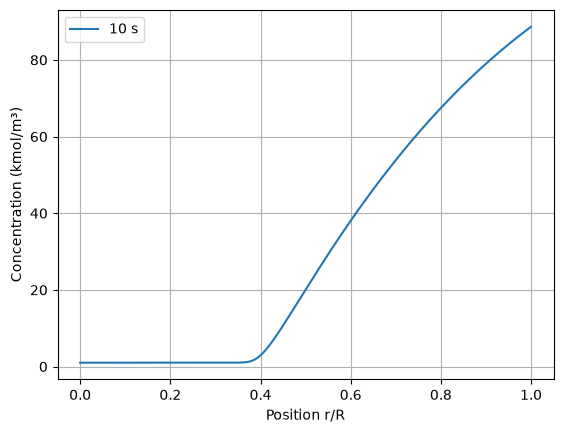

In [ ]:
from firedrake import *
import numpy as np
import matplotlib.pyplot as plt

# Solid cylinder, radial symmetry, plane strain and a traction-free surface.
# Implements Eq. (11) through its weak form, Eq. (14), with mechanics Eq. (12).
# Run in serial for the simple nodal plotting below.

#  the mixed form w = Laplacian(q). Set kc = 0 to recover the original model.

## Input parameters
E = Constant(80e9)         # Young's modulus, Pa
nu = Constant(0.22)        # Poisson's ratio
Omega = Constant(8.5e-6)   # Partial molar volume, m³/mol
T = Constant(298.15)       # Temperature, K
R_g = Constant(8.3076)     # N_A * k_B, using the paper's constants, J/(mol K)
D = Constant(2.057235e-18) # M * k_B * T from the paper, m²/s
R = 100e-9                 # Cylinder radius, m

c0 = 1.0                   # Initial concentration, kmol/m³
cmax = 88.67               # Fixed surface concentration, kmol/m³
dc = cmax - c0
dt = 0.01                 # Time step, s
sample_times = [10]

#  gradient-energy coefficient kc of Eq. (1); the paper gives no value, so this is assumed.
#  it sets a gradient length l_c = sqrt(kc/(R_g T)) (about 4.5 nm here).
kc = Constant(5e-14)       # J m²/mol, assumed 
print(f"l_c = {np.sqrt(float(kc)/(float(R_g)*float(T)))*1e9:.2f} nm")

#  the surface concentration is raised from c0 to cmax over t_ramp seconds
# instead of jumping there in the first step (see the note at the BCs).
t_ramp = 1.0               # : ramp time, s, short compared with the 10 s run
q_surf = Constant(0.0)     #  surface value of q, updated every step


## Mesh and FE settings
n_ele = 160
mesh = IntervalMesh(n_ele, 1.0)
x = SpatialCoordinate(mesh)[0]  # x = r/R

V_u = FunctionSpace(mesh, "CG", 2)  # Quadratic radial displacement
V_c = FunctionSpace(mesh, "CG", 2)  # Quadratic normalized concentration
V_w = FunctionSpace(mesh, "CG", 2)  #  w = Laplacian of q in x
W = V_u * V_c * V_w                 #  third field w because CG cannot hold the Biharmonic operator

# u = physical radial displacement / R; q = (c - c0)/(cmax - c0).
state = Function(W)
u, q, w = split(state)                  
del_u, del_q, del_w = TestFunctions(W)  
q_p = Function(V_c).assign(0.0)
c = c0 + dc * q

# Fixed quadrature also avoids evaluating u/x at the centre itself.
dV = dx(metadata={"quadrature_degree": 8})

## Strain and stress tensors
lmbda = E * nu / ((1 + nu) * (1 - 2*nu))
mu = E / (2 * (1 + nu))

def epsilon(u):
    # Radial, circumferential and axial components (plane strain).
    return as_tensor([[u.dx(0), 0, 0],
                      [0, u/x, 0],
                      [0, 0, 0]])

def sigma(u, c):
    swelling = Omega * (1000 * (c - c0)) / 3  # kmol/m³ -> mol/m³
    elastic_strain = epsilon(u) - swelling * Identity(3)
    return lmbda * tr(elastic_strain) * Identity(3) + 2 * mu * elastic_strain

stress = sigma(u, c)
sigma_h = tr(stress) / 3  # Hydrostatic stress, Pa

## Boundary conditions
# FIX: a jump from c0 to cmax in one step makes q dip below 0 next to the surface
# (the 4th-order term overshoots at the sharp front). Where c < 0 the drift and kc
# terms flip sign (anti-diffusion), so Newton cannot converge. Ramping avoids the jump.
bcs = [DirichletBC(W.sub(0), 0.0, 1),     # u_r = 0 at the centre
       DirichletBC(W.sub(1), q_surf, 2),  #  ramped surface value, reaches cmax at t = t_ramp
       DirichletBC(W.sub(2), 0.0, 2)]     #  w = Laplacian(q) = 0 at the surface (assumed 2nd condition)

## Weak form
# Mechanical equilibrium, Eq. (13), with radial volume weight x.
F_mech = x * inner(stress / E, epsilon(del_u)) * dV

# w = (1/x) d/dx(x dq/dx). Multiply by x*del_w and integrate by parts;
# the x = 0 term has the factor x, and at x = 1 del_w = 0 because w is fixed.

F_lap = x * (w * del_w + q.dx(0) * del_w.dx(0)) * dV

# Diffusion, Eq. (14).

# derivative jumps there and Newton bounces back and forth; with the ramp c stays >= c0 anyway.
# the two kc terms of Eq. (11) are together -div[(D kc/(R_g T cmax)) c grad(Lap c)].
# In scaled form this adds -(kc/(R_g T R²)) (c/cmax) w' to the flux.
F_diff = x * (
    (q - q_p) * del_q / dt
    + (D / R**2) * (
        q.dx(0) - (Omega / (R_g * T)) * (c / dc) * sigma_h.dx(0)
        - (kc / (R_g * T * R**2)) * (c / cmax) * w.dx(0)  #  gradient-energy flux need to be accounted in flux
    ) * del_q.dx(0)
) * dV


#note here: F_lap is the only place in the code that says w = lap(q)
F = F_mech + F_diff + F_lap
problem = NonlinearVariationalProblem(F, state, bcs=bcs)
solver = NonlinearVariationalSolver(problem, solver_parameters={
    "snes_type": "newtonls",
    "snes_linesearch_type": "bt",
    "snes_rtol": 1e-9,
    "snes_atol": 1e-11,
    "snes_max_it": 50,
    "mat_type": "aij",
    "ksp_type": "preonly",
    "pc_type": "lu",
})

u_h, q_h, w_h = state.subfunctions
node = Function(V_c).interpolate(x).dat.data_ro.copy()
order = np.argsort(node)  # Match concentration values to ascending radius
node = node[order]
profiles = {}
sample_steps = {round(time / dt): time for time in sample_times}

for step in range(1, max(sample_steps) + 1):
    q_surf.assign(min(step * dt / t_ramp, 1.0))  # ramp the surface value, then hold it at 1
    solver.solve()

    if step in sample_steps:
        time = sample_steps[step]
        profiles[time] = c0 + dc * q_h.dat.data_ro.copy()[order]
        print(f"Saved concentration at {time:g} s")

    q_p.assign(q_h)

## Plot concentration against radius
for time, concentration in profiles.items():
    plt.plot(node, concentration, label=f"{time:g} s")

plt.xlabel("Position r/R")
plt.ylabel("Concentration (kmol/m³)")
plt.legend()
plt.grid(True)
plt.show()

"""
Barely any changing of the concentration profile is seen over 10 s, which is consistent with the expected result
fourth order gradient energy turn only acts here to smooth out the concentration profile slightly.
"""